--- Temperaturstatistikk Ås (2025) ---
 Mean  Median   Min  Max
  7.9     8.4 -15.5 23.7


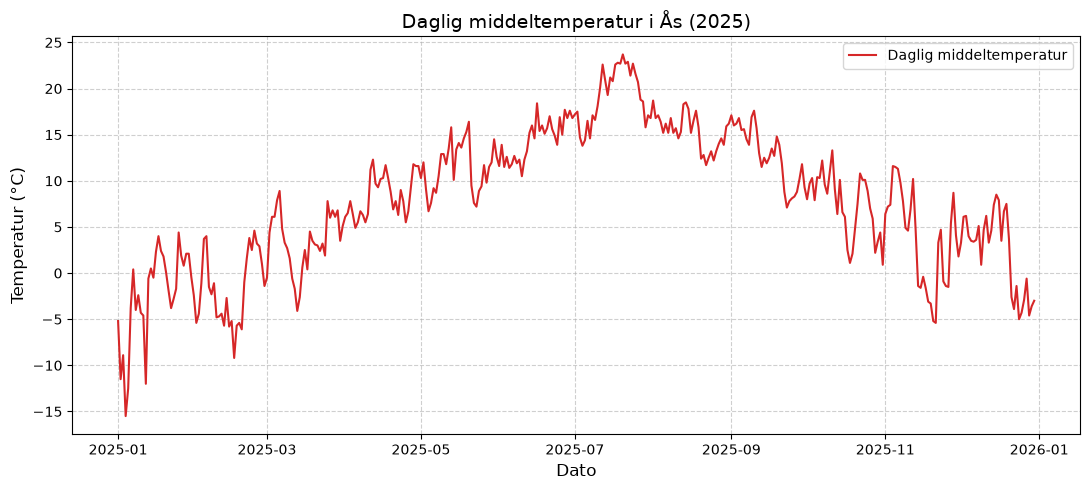

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import requests

# 1. Les inn din skjulte Client-ID fra tekstfilen
with open('../client_id.txt', 'r') as f:
    client_id = f.read().strip()

# 2. Definer endepunkt og parametere spesifisert i oppgaven
endpoint = 'https://frost.met.no/observations/v0.jsonld'
parameters = {
    'sources': 'SN17850',                    # Værstasjon for Ås
    'elements': 'mean(air_temperature P1D)', # Daglig middeltemperatur
    'referencetime': '2025-01-01/2025-12-31' # Hele året 2025
}

# 3. Hent data fra Frost API
r = requests.get(endpoint, parameters, auth=(client_id, ''))
json_data = r.json()

# Sjekk at forespørselen gikk bra
if r.status_code == 200:
    # 4. Pakk ut observasjonsdataene til en DataFrame
    data_list = []
    for item in json_data['data']:
        data_list.append({
            'referenceTime': item['referenceTime'],
            'temperature': item['observations'][0]['value']
        })

    df_2025 = pd.DataFrame(data_list)
    df_2025['referenceTime'] = pd.to_datetime(df_2025['referenceTime'])

    # 5. Lag sammendragstabell med mean, median, min og max[cite: 1]
    summary_table = pd.DataFrame({
        'Mean': [df_2025['temperature'].mean()],
        'Median': [df_2025['temperature'].median()],
        'Min': [df_2025['temperature'].min()],
        'Max': [df_2025['temperature'].max()]
    })

    # Skriv ut tabellen med print()
    print("--- Temperaturstatistikk Ås (2025) ---")
    print(summary_table.round(2).to_string(index=False))

    # 6. Lag plott for daglig middeltemperatur (tid på x-aksen, temp på y-aksen)[cite: 1]
    plt.figure(figsize=(11, 5))
    plt.plot(df_2025['referenceTime'], df_2025['temperature'], color='tab:red', linewidth=1.5, label='Daglig middeltemperatur')
    
    plt.title('Daglig middeltemperatur i Ås (2025)', fontsize=14)
    plt.xlabel('Dato', fontsize=12)
    plt.ylabel('Temperatur (°C)', fontsize=12)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend()
    plt.tight_layout()
    plt.show()

else:
    print(f"Feil ved henting av data. Statuskode: {r.status_code}")
    print(json_data.get('error', {}).get('message', 'Ukjent feil'))